# CSE 366: Artificial Intelligence / Machine Learning Project
## Submission 2: Pretrained CNN Models, With and Without Fine-Tuning
**Group 3 · Department of CSE, East West University**
**Domain:** Precision agriculture and computer vision for foliar disease diagnosis
**Dataset:** PlantVillage (Kaggle `emmarex/plantdisease`), the same 15-class subset as Submission 1: Pepper (2 classes), Potato (3) and Tomato (10), 20,638 RGB leaf images

### What this notebook delivers (roadmap, Submission 2)
| Requirement | Where |
|---|---|
| At least three pretrained architectures, 30–50 epochs | **MobileNetV2, ResNet-18, ShuffleNetV2**, 30 epochs each, Section 6 |
| With and without fine-tuning | every model is run in both modes |
| Fix over- or underfitting if it occurs | Section 7 (diagnosis table) and the written analysis |
| Accuracy curve and loss curve, train vs validation | one figure per experiment |
| Classification report (precision, recall, F1 per class) | printed for every experiment |
| Confusion matrix on the test set | one per experiment |
| Accuracy, precision, recall, F1, training time, testing time | printed per experiment and collected in the Section 7 table |

---
## 1. Environment and configuration
Every submission uses the same configuration, the same random seed and the same stratified 70/15/15 split, so results are comparable across notebooks.

> **Compute note.** This notebook was executed on a CPU-only machine (2 cores, no GPU). To keep the full protocol feasible there, images are resized to **64 × 64** instead of the usual 224 × 224. The only thing to change for a higher-resolution run on a GPU (for example Google Colab) is `IMG_SIZE` in the cell below; the image cache is rebuilt automatically.

In [1]:
# ---- Imports, configuration and reproducibility (identical in every submission) ----
import os, sys, time, json, copy, math, random, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as tvm
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except Exception:                       # plain-python fallback
    display = lambda obj: print(obj.to_string() if hasattr(obj, "to_string") else obj)

# ------------------------- Global configuration -------------------------
SEED       = 42        # seed for the data split and for training
IMG_SIZE   = 64        # input resolution (64 keeps CPU training feasible; use 128 or 224 on a GPU)
BATCH_SIZE = 64
VAL_FRAC   = 0.15      # stratified 70 / 15 / 15 split
TEST_FRAC  = 0.15
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(os.cpu_count() or 2)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)

# ------------------------- Plot theme (soft pastel palette) -------------------------
PAL = {"rose": "#E7A3B6", "mint": "#A9D9C3", "blue": "#A8C8E8", "yellow": "#F4DC8A",
       "rose_d": "#C25A7B", "mint_d": "#4E9E7E", "blue_d": "#4A7FB5", "yellow_d": "#C79D1E",
       "ink": "#3B3B4F", "grid": "#E6E2EA"}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 110, "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.edgecolor": PAL["ink"], "axes.labelcolor": PAL["ink"], "text.color": PAL["ink"],
    "xtick.color": PAL["ink"], "ytick.color": PAL["ink"], "axes.grid": True,
    "grid.color": PAL["grid"], "axes.facecolor": "#FFFEFC", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False})
CM_CMAP   = LinearSegmentedColormap.from_list("pastel_cm",   ["#FFFFFF", PAL["blue"], PAL["blue_d"]])
HEAT_CMAP = LinearSegmentedColormap.from_list("pastel_heat", [PAL["rose"], PAL["yellow"], PAL["mint"]])

print(f"PyTorch {torch.__version__} | device: {DEVICE} | CPU threads: {torch.get_num_threads()} "
      f"| input size: {IMG_SIZE}x{IMG_SIZE} | batch size: {BATCH_SIZE} | seed: {SEED}")

PyTorch 2.14.1+cpu | device: cpu | CPU threads: 2 | input size: 64x64 | batch size: 64 | seed: 42


---
## 2. Dataset, preprocessing and split
The dataset is loaded from the Kaggle archive used in Submission 1 (folders `archive/PlantVillage/<class>/`). A zero-byte placeholder file in the Yellow Leaf Curl Virus folder is skipped, which gives exactly the **20,638** images counted in Submission 1.

* **Resize:** 256 × 256 → `IMG_SIZE` × `IMG_SIZE` (bilinear); **Normalise:** ImageNet mean and standard deviation (as planned in Submission 1, and required by the pretrained backbones).
* **Stratified 70 / 15 / 15 split** with a fixed seed, so every class appears in train, validation and test in the same proportion.
* **Class weights:** inverse-frequency weights in the loss counter the 21 : 1 imbalance found in the EDA (smallest class: Potato healthy, 152 images).

In [2]:
# ---- Load PlantVillage (same 15 classes as Submission 1) and build the shared split ----
SHORT = {
    "Pepper__bell___Bacterial_spot": "Pepper Bacterial spot", "Pepper__bell___healthy": "Pepper healthy",
    "Potato___Early_blight": "Potato Early blight", "Potato___Late_blight": "Potato Late blight",
    "Potato___healthy": "Potato healthy", "Tomato_Bacterial_spot": "Tomato Bacterial spot",
    "Tomato_Early_blight": "Tomato Early blight", "Tomato_Late_blight": "Tomato Late blight",
    "Tomato_Leaf_Mold": "Tomato Leaf mold", "Tomato_Septoria_leaf_spot": "Tomato Septoria spot",
    "Tomato_Spider_mites_Two_spotted_spider_mite": "Tomato Spider mites",
    "Tomato__Target_Spot": "Tomato Target spot", "Tomato__Tomato_YellowLeaf__Curl_Virus": "Tomato Yellow leaf curl",
    "Tomato__Tomato_mosaic_virus": "Tomato Mosaic virus", "Tomato_healthy": "Tomato healthy"}
IMG_EXT = {".jpg", ".jpeg", ".png"}
CACHE_DIR = Path(os.environ.get("PV_CACHE_DIR", "."))

def _is_dataset_dir(p):
    return p.is_dir() and sum(d.is_dir() for d in p.iterdir()) >= 15

def find_dataset_dir():
    candidates = [os.environ.get("PV_DATA_DIR", ""), "/content/archive/PlantVillage", "/content/PlantVillage",
                  "/content/drive/MyDrive/PlantVillage", "/content/drive/MyDrive/archive/PlantVillage",
                  "archive/PlantVillage", "PlantVillage", "../archive/PlantVillage", "data/PlantVillage"]
    for c in candidates:
        if c and _is_dataset_dir(Path(c)):
            return Path(c)
    try:  # Colab or any machine with internet access: fetch the same Kaggle dataset
        import kagglehub
        root = Path(kagglehub.dataset_download("emmarex/plantdisease"))
        for p in [root / "PlantVillage", *root.rglob("PlantVillage")]:
            if _is_dataset_dir(p):
                return p
    except Exception as e:
        print("kagglehub download failed:", e)
    raise FileNotFoundError("PlantVillage folder not found. Download 'emmarex/plantdisease' from Kaggle "
                            "and place it at archive/PlantVillage (or set PV_DATA_DIR).")

def build_cache(data_dir, img_size, cache_path):
    class_dirs = [d for d in sorted(data_dir.iterdir()) if d.is_dir() and d.name != "PlantVillage"]
    X, y, names = [], [], [d.name for d in class_dirs]
    for ci, d in enumerate(class_dirs):
        files = sorted(f for f in d.iterdir() if f.is_file() and f.suffix.lower() in IMG_EXT and f.stat().st_size > 0)
        for f in files:
            with Image.open(f) as im:
                X.append(np.asarray(im.convert("RGB").resize((img_size, img_size), Image.Resampling.BILINEAR)))
            y.append(ci)
        print(f"  loaded {len(files):5d} images  <-  {d.name}")
    np.savez(cache_path, X=np.stack(X).astype(np.uint8), y=np.array(y, dtype=np.int64), names=np.array(names))

DATA_DIR = find_dataset_dir()
print("Active dataset directory:", DATA_DIR)
cache_path = CACHE_DIR / f"plantvillage_{IMG_SIZE}px.npz"
if not cache_path.exists():
    print(f"Building a {IMG_SIZE}x{IMG_SIZE} image cache (one-off) ...")
    t0 = time.time(); build_cache(DATA_DIR, IMG_SIZE, cache_path); print(f"cache built in {time.time()-t0:.0f}s")
z = np.load(cache_path)
X_all, y_all, CLASS_NAMES = z["X"], z["y"], [str(n) for n in z["names"]]
NUM_CLASSES = len(CLASS_NAMES)
LABELS = [SHORT.get(n, n.replace("_", " ")) for n in CLASS_NAMES]
print(f"\nImages: {len(y_all):,} | classes: {NUM_CLASSES} | tensor shape per image: {tuple(X_all.shape[1:])} (H, W, RGB)")

# ---- Stratified 70 / 15 / 15 split (fixed seed, so every submission uses the same test set) ----
idx_all = np.arange(len(y_all))
idx_tr, idx_tmp = train_test_split(idx_all, test_size=VAL_FRAC + TEST_FRAC, stratify=y_all, random_state=SEED)
idx_va, idx_te = train_test_split(idx_tmp, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
                                  stratify=y_all[idx_tmp], random_state=SEED)
assert not (set(idx_tr) & set(idx_va)) and not (set(idx_tr) & set(idx_te)) and not (set(idx_va) & set(idx_te))

def to_tensor(idx):
    return torch.from_numpy(X_all[idx]).permute(0, 3, 1, 2).contiguous(), torch.from_numpy(y_all[idx])
X_tr, y_tr = to_tensor(idx_tr); X_va, y_va = to_tensor(idx_va); X_te, y_te = to_tensor(idx_te)

split_df = pd.DataFrame({"Class": LABELS,
                         "Train": np.bincount(y_tr.numpy(), minlength=NUM_CLASSES),
                         "Val":   np.bincount(y_va.numpy(), minlength=NUM_CLASSES),
                         "Test":  np.bincount(y_te.numpy(), minlength=NUM_CLASSES)})
split_df["Total"] = split_df[["Train", "Val", "Test"]].sum(axis=1)
split_df.loc[len(split_df)] = ["ALL CLASSES", *split_df[["Train", "Val", "Test", "Total"]].sum().tolist()]
print(f"\nStratified split -> train {len(y_tr):,} | validation {len(y_va):,} | test {len(y_te):,}")
display(split_df)

# ---- Class weights (inverse frequency) to counter the 21:1 imbalance found in the EDA ----
train_counts = np.bincount(y_tr.numpy(), minlength=NUM_CLASSES)
CLASS_W = torch.tensor(len(y_tr) / (NUM_CLASSES * train_counts), dtype=torch.float32)
print("\nClass weights (largest for the rarest classes):")
print(pd.Series(CLASS_W.numpy().round(2), index=LABELS).sort_values(ascending=False).head(5).to_string())

Active dataset directory: archive/PlantVillage



Images: 20,638 | classes: 15 | tensor shape per image: (64, 64, 3) (H, W, RGB)



Stratified split -> train 14,446 | validation 3,096 | test 3,096


,Class,Train,Val,Test,Total
0,Pepper Bacterial spot,698,150,149,997
1,Pepper healthy,1035,222,221,1478
2,Potato Early blight,700,150,150,1000
3,Potato Late blight,700,150,150,1000
4,Potato healthy,106,23,23,152
5,Tomato Bacterial spot,1489,319,319,2127
6,Tomato Early blight,700,150,150,1000
7,Tomato Late blight,1336,286,287,1909
8,Tomato Leaf mold,666,143,143,952
9,Tomato Septoria spot,1240,265,266,1771



Class weights (largest for the rarest classes):
Potato healthy         9.09
Tomato Mosaic virus    3.69
Tomato Leaf mold       1.45
Tomato Early blight    1.38
Potato Late blight     1.38


---
## 3. Data augmentation and the training loop
Augmentation is implemented as fast batch operations on the training images only (validation and test images are never augmented). The transforms follow the plan written in Submission 1, scaled to the lower resolution:

| Type | Setting |
|---|---|
| Flips | horizontal and vertical, p = 0.5 each |
| Rotation | ±30° (reflection padding) |
| Zoom / random crop | keeps 80–100 % of the field of view, random position |
| Photometric | brightness, contrast and saturation ±20 % |
| Random erasing | p = 0.2, noise-filled rectangle covering 2–15 % of the image |

In [3]:
# ---- Preprocessing, data augmentation and the shared training loop ----
MEAN = torch.tensor(IMAGENET_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor(IMAGENET_STD,  device=DEVICE).view(1, 3, 1, 1)

def prep_eval(xb):
    """uint8 [B,3,H,W] -> ImageNet-normalised float tensor (no augmentation)."""
    return (xb.float() / 255.0 - MEAN) / STD

def augment(x):
    """Batch augmentation on float images in [0,1]; follows the plan written in Submission 1:
    flips (p=0.5), rotation +-30 deg, random zoom/crop (scale 0.8-1.0), brightness/contrast/saturation +-0.2,
    random erasing (p=0.2)."""
    B, _, H, W = x.shape; dev = x.device
    x = torch.where((torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1), x.flip(3), x)       # horizontal flip
    x = torch.where((torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1), x.flip(2), x)       # vertical flip
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(30)                              # rotation
    s = torch.empty(B, device=dev).uniform_(0.8, 1.0)                                          # zoom (fraction of view kept)
    tx = (torch.rand(B, device=dev) * 2 - 1) * (1 - s); ty = (torch.rand(B, device=dev) * 2 - 1) * (1 - s)
    cos, sin = torch.cos(ang) * s, torch.sin(ang) * s
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False),
                      mode="bilinear", padding_mode="reflection", align_corners=False)
    jit = lambda: 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.2                      # +-20 %
    x = x * jit()                                                                              # brightness
    m = x.mean(dim=(1, 2, 3), keepdim=True); x = (x - m) * jit() + m                           # contrast
    g = x.mean(dim=1, keepdim=True); x = (x - g) * jit() + g                                   # saturation
    x = x.clamp(0, 1)
    area = torch.empty(B, device=dev).uniform_(0.02, 0.15) * H * W                             # random erasing
    ratio = torch.empty(B, device=dev).uniform_(0.3, 3.3)
    eh = (area * ratio).sqrt().clamp(1, H).long(); ew = (area / ratio).sqrt().clamp(1, W).long()
    y0 = (torch.rand(B, device=dev) * (H - eh + 1)).long(); x0 = (torch.rand(B, device=dev) * (W - ew + 1)).long()
    ys = torch.arange(H, device=dev).view(1, H, 1); xs = torch.arange(W, device=dev).view(1, 1, W)
    box = (ys >= y0.view(B, 1, 1)) & (ys < (y0 + eh).view(B, 1, 1)) & (xs >= x0.view(B, 1, 1)) & (xs < (x0 + ew).view(B, 1, 1))
    box = box & (torch.rand(B, device=dev) < 0.2).view(B, 1, 1)
    return torch.where(box.unsqueeze(1), torch.rand_like(x), x)

def prep_train(xb):
    return (augment(xb.float() / 255.0) - MEAN) / STD

identity = lambda t: t   # used when the inputs are already feature vectors

class Logger:
    """Prints and records every line so a finished experiment can be replayed from disk."""
    def __init__(self): self.lines = []
    def __call__(self, s=""): print(s, flush=True); self.lines.append(str(s))

def channels_last(model):
    """Use the channels-last memory layout (about 1.3-1.5x faster on CPU for small / depthwise networks; same results)."""
    model.to(memory_format=torch.channels_last)
    for m in model.modules(): m._cl = True
    return model

def _fmt(x, model):
    return x.contiguous(memory_format=torch.channels_last) if getattr(model, "_cl", False) and x.dim() == 4 else x

def _sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def evaluate(model, X, y, loss_fn, prep, bs=256):
    """Loss and accuracy on a split (used for validation after every epoch)."""
    model.eval(); tot, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(_fmt(prep(X[i:i + bs].to(DEVICE)), model)); yb = y[i:i + bs].to(DEVICE)
        tot += loss_fn(out, yb).item() * len(yb); correct += (out.argmax(1) == yb).sum().item()
    return tot / len(X), correct / len(X)

@torch.no_grad()
def predict_timed(model, X, prep, bs=256):
    """Predictions plus the wall-clock time of the forward passes (= testing time)."""
    model.eval(); preds = []; _sync(); t0 = time.perf_counter()
    for i in range(0, len(X), bs):
        preds.append(model(_fmt(prep(X[i:i + bs].to(DEVICE)), model)).argmax(1).cpu())
    _sync(); return torch.cat(preds).numpy(), time.perf_counter() - t0

def fit(model, data, epochs, optimizer, loss_fn, train_prep, eval_prep, scheduler=None, plateau=False,
        patience=None, min_epochs=5, seed=SEED, log=print):
    """Train for up to `epochs`; keep the weights of the best validation loss.
    Early stopping triggers after `patience` epochs without improvement (never before `min_epochs`)."""
    Xtr, ytr, Xva, yva = data
    model.to(DEVICE)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr", "epoch_sec"]}
    best = {"val_loss": float("inf"), "epoch": 0, "state": None}; bad = 0; stopped_early = False
    gen = torch.Generator().manual_seed(seed)
    _sync(); t_fit = time.perf_counter()
    for ep in range(1, epochs + 1):
        t_ep = time.perf_counter(); model.train()
        perm = torch.randperm(len(Xtr), generator=gen)
        run_loss = run_ok = seen = 0
        for i in range(0, len(perm), BATCH_SIZE):
            bi = perm[i:i + BATCH_SIZE]
            if len(bi) < 2: continue                      # BatchNorm needs more than one sample
            xb = _fmt(train_prep(Xtr[bi].to(DEVICE)), model); yb = ytr[bi].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            out = model(xb); loss = loss_fn(out, yb); loss.backward(); optimizer.step()
            run_loss += loss.item() * len(bi); run_ok += (out.argmax(1) == yb).sum().item(); seen += len(bi)
        vl, va = evaluate(model, Xva, yva, loss_fn, eval_prep)
        lr_now = optimizer.param_groups[0]["lr"]
        if scheduler is not None:
            scheduler.step(vl) if plateau else scheduler.step()
        _sync(); sec = time.perf_counter() - t_ep
        for k, v in zip(hist, [run_loss / seen, run_ok / seen, vl, va, lr_now, sec]): hist[k].append(v)
        if vl < best["val_loss"] - 1e-4:
            best.update(val_loss=vl, epoch=ep, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}); bad = 0
        else:
            bad += 1
        log(f"Epoch {ep:02d}/{epochs} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.4f} | "
            f"val loss {vl:.4f} acc {va:.4f} | lr {lr_now:.1e} | {sec:5.1f}s" + ("  *best*" if best["epoch"] == ep else ""))
        if patience is not None and bad >= patience and ep >= min_epochs:
            stopped_early = True; log(f"Early stopping at epoch {ep}: no val-loss improvement for {patience} epochs "
                                      f"(best epoch = {best['epoch']})."); break
    _sync(); train_sec = time.perf_counter() - t_fit
    model.load_state_dict(best["state"])                  # restore the best checkpoint
    return {"hist": hist, "best_epoch": best["epoch"], "epochs_run": len(hist["val_loss"]),
            "train_sec": train_sec, "stopped_early": stopped_early}

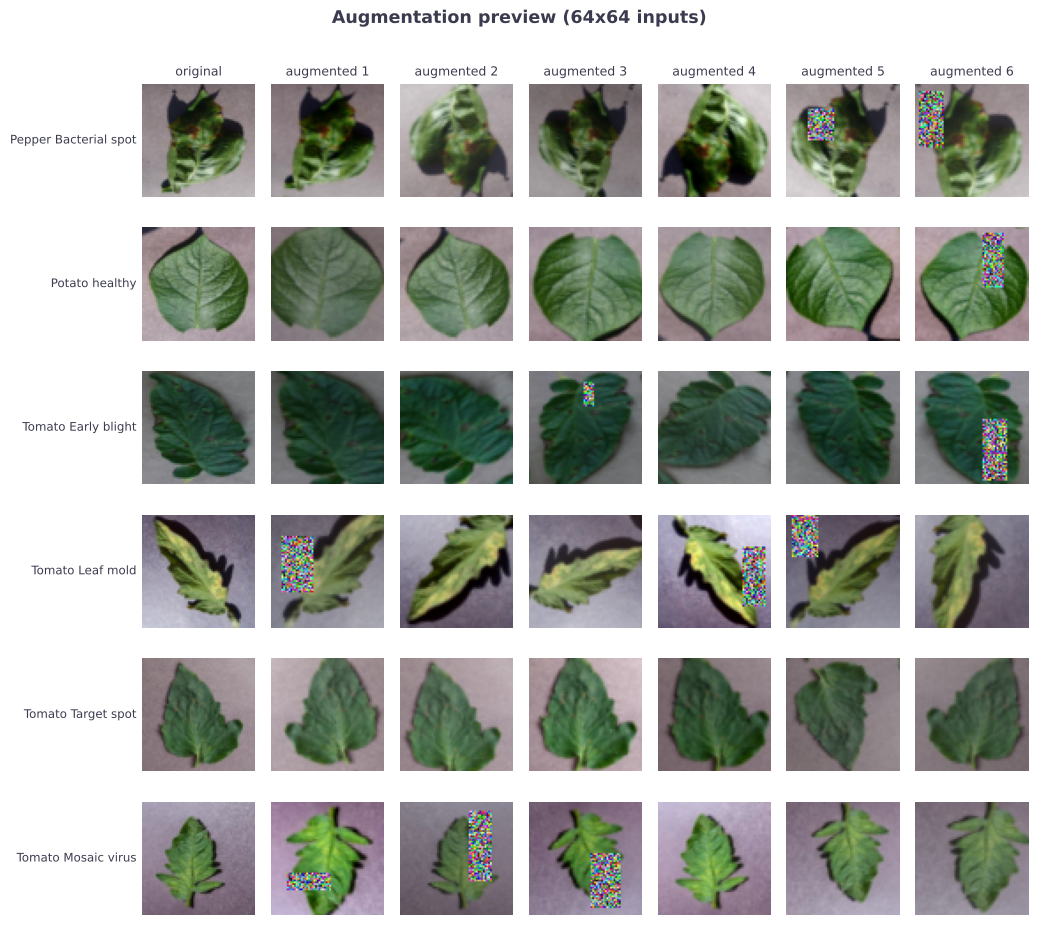

In [4]:
# ---- Preview of the augmentation pipeline (applied to training images only) ----
set_seed(SEED)
shown = [int(np.where(y_tr.numpy() == c)[0][0]) for c in (0, 4, 6, 8, 11, 13)]
fig, axes = plt.subplots(len(shown), 7, figsize=(10.5, 1.55 * len(shown)))
for r, i in enumerate(shown):
    base = X_tr[i:i + 1].to(DEVICE)
    axes[r, 0].imshow(base[0].permute(1, 2, 0).cpu().numpy())
    axes[r, 0].set_ylabel(LABELS[int(y_tr[i])], rotation=0, ha="right", va="center", fontsize=8.5)
    for c in range(1, 7):
        axes[r, c].imshow(augment(base.float() / 255.0)[0].permute(1, 2, 0).cpu().numpy())
    for c in range(7):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
        for s in axes[r, c].spines.values(): s.set_visible(False)
    if r == 0:
        axes[r, 0].set_title("original", fontsize=9)
        for c in range(1, 7): axes[r, c].set_title(f"augmented {c}", fontsize=9)
plt.suptitle(f"Augmentation preview ({IMG_SIZE}x{IMG_SIZE} inputs)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

---
## 4. Evaluation utilities
The same code is used in all submissions. The training loop (`fit`) trains with a validation pass after every epoch and keeps the weights of the epoch with the lowest validation loss. `report_experiment` prints accuracy, precision, recall and F1 (macro and weighted), the per-class classification report, **training time** and **testing time**, then draws the accuracy and loss curves and the confusion matrix.

In [5]:
# ---- Evaluation helpers: metrics, classification report, curves, confusion matrix ----
RESULT_DIR = Path(os.environ.get("PV_RESULT_DIR", "results")); RESULT_DIR.mkdir(exist_ok=True, parents=True)
RESUME = os.environ.get("PV_RESUME", "0") == "1"      # only used to continue an interrupted run

def count_params(model):
    tot = sum(p.numel() for p in model.parameters()); trn = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return tot, trn

def metric_row(y_true, y_pred):
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision_macro": pm, "recall_macro": rm, "f1_macro": fm,
            "precision_weighted": pw, "recall_weighted": rw, "f1_weighted": fw}

def plot_curves(hist, title, best_epoch=None):
    ep = np.arange(1, len(hist["val_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
    for a, k, name in [(ax[0], "acc", "Accuracy"), (ax[1], "loss", "Loss")]:
        a.plot(ep, hist[f"train_{k}"], color=PAL["rose_d"], lw=2, marker="o", ms=3, label="train")
        a.plot(ep, hist[f"val_{k}"], color=PAL["blue_d"], lw=2, marker="o", ms=3, label="validation")
        if best_epoch: a.axvline(best_epoch, color=PAL["yellow_d"], ls="--", lw=1.4, label=f"best epoch ({best_epoch})")
        a.set_xlabel("epoch"); a.set_ylabel(name); a.set_title(f"{name} curve"); a.legend(frameon=False)
        a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    fig.suptitle(title, fontweight="bold", y=1.03); plt.tight_layout(); plt.show()

def plot_confusion(cm, title, fontsize=7.5):
    fig, ax = plt.subplots(figsize=(10.5, 8.6))
    ax.imshow(cm, cmap=CM_CMAP, vmin=0, vmax=max(1, cm.max())); ax.grid(False)
    ax.set_xticks(range(len(LABELS))); ax.set_yticks(range(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=55, ha="right", fontsize=8.5); ax.set_yticklabels(LABELS, fontsize=8.5)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j]:
                ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=fontsize,
                        color="white" if cm[i, j] > 0.55 * cm.max() else PAL["ink"])
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title, fontweight="bold")
    for s in ax.spines.values(): s.set_visible(True)
    plt.tight_layout(); plt.show()

def report_experiment(rec, show_plots=True):
    """Print metrics + classification report and draw curves and the confusion matrix for one finished experiment."""
    m = rec["metrics"]
    print(f"=== {rec['name']} ===")
    print(f"Parameters: {rec['params_total']:,} total, {rec['params_trainable']:,} trainable | "
          f"epochs run: {rec['epochs_run']} | best epoch (lowest val loss): {rec['best_epoch']}"
          + (" | stopped early" if rec.get("stopped_early") else ""))
    print(f"Accuracy {m['accuracy']:.4f} | Precision(macro) {m['precision_macro']:.4f} | Recall(macro) {m['recall_macro']:.4f} | "
          f"F1(macro) {m['f1_macro']:.4f} | F1(weighted) {m['f1_weighted']:.4f}")
    print(f"Training time: {rec['train_sec']:.1f} s ({rec['train_sec']/60:.1f} min) | "
          f"Testing time: {rec['test_sec']:.2f} s for {rec['n_test']:,} test images ({1000*rec['test_sec']/rec['n_test']:.2f} ms/image)\n")
    print("Classification report (test set):"); print(rec["report"])
    if show_plots:
        plot_curves(rec["hist"], f"{rec['name']}: training vs validation", rec["best_epoch"])
        plot_confusion(rec["cm"], f"{rec['name']}: confusion matrix (test set, n={rec['n_test']:,})")

def make_record(name, model, fit_out, y_true, y_pred, test_sec, log, **extra):
    tot, trn = count_params(model)
    rec = {"name": name, "hist": fit_out["hist"], "best_epoch": fit_out["best_epoch"], "epochs_run": fit_out["epochs_run"],
           "stopped_early": fit_out["stopped_early"], "train_sec": fit_out["train_sec"] + extra.pop("extra_train_sec", 0.0),
           "test_sec": test_sec, "n_test": len(y_true), "params_total": tot, "params_trainable": trn,
           "metrics": metric_row(y_true, y_pred), "cm": confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES)),
           "y_pred": np.asarray(y_pred), "y_true": np.asarray(y_true),
           "report": classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=LABELS, digits=4, zero_division=0),
           "per_class_f1": precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)[2],
           "log": list(log.lines)}
    rec.update(extra); return rec

def save_record(rec, fname):
    with open(RESULT_DIR / fname, "wb") as f: pickle.dump(rec, f)

def load_record(fname):
    with open(RESULT_DIR / fname, "rb") as f: return pickle.load(f)

def top_confusions(cm, k=8):
    """The k most frequent mistakes (true class -> predicted class)."""
    off = cm.copy(); np.fill_diagonal(off, 0)
    order = np.argsort(-off.ravel())[:k]
    rows = [{"True class": LABELS[i], "Predicted as": LABELS[j], "Images": int(off[i, j])}
            for i, j in zip(*np.unravel_index(order, off.shape)) if off[i, j] > 0]
    return pd.DataFrame(rows)

---
## 5. Experimental design
Three ImageNet-pretrained architectures from `torchvision` were chosen to cover different design ideas while staying small enough to train on a CPU:

| Model | Idea | Feature size |
|---|---|---|
| **MobileNetV2** | inverted residual blocks with depthwise convolutions (built for phones, relevant for farmers' devices) | 1280 |
| **ResNet-18** | classic residual learning | 512 |
| **ShuffleNetV2 (1.0×)** | channel split and shuffle for very fast inference | 1024 |

Each model is trained in two modes with identical data, augmentation, loss, seed and **30 epochs**:

| | **No fine-tuning** | **Fine-tuned** |
|---|---|---|
| Backbone | frozen (ImageNet weights, eval mode) | all layers trained |
| What is learned | new head only (dropout 0.2 + linear layer) | backbone and head |
| How | backbone features are computed once; the head is trained on them | full back-propagation with augmentation every epoch |
| Optimiser | AdamW, lr 1e-3, weight decay 1e-4, cosine schedule | AdamW, lr 3e-4 (backbone) and 1e-3 (head), weight decay 1e-4, cosine schedule |
| Training time reported | feature extraction + 30 head epochs | all 30 epochs including the per-epoch validation pass |

*Frozen-backbone runs use cached features, so augmentation is not applied in that mode; this is the standard, cheapest way to train a frozen network and makes the comparison "how much does fine-tuning add" very direct.* Loss for both modes is class-weighted cross-entropy. The reported test result always uses the checkpoint with the lowest validation loss.

In [6]:
# ---- Pretrained backbones (ImageNet weights) and the experiment runner ----
PRETRAINED = ["MobileNetV2", "ResNet-18", "ShuffleNetV2"]
EPOCHS = 30                                   # roadmap: 30-50 epochs
LOSS_FN = nn.CrossEntropyLoss(weight=CLASS_W.to(DEVICE))
RESULTS = []                                  # filled by the experiment cells below
CHANNELS_LAST = {"MobileNetV2": True, "ResNet-18": False, "ShuffleNetV2": True}   # memory layout chosen for speed on CPU; no effect on results

def make_backbone(name):
    if name == "MobileNetV2":
        m = tvm.mobilenet_v2(weights=tvm.MobileNet_V2_Weights.IMAGENET1K_V1)
        return nn.Sequential(m.features, nn.AdaptiveAvgPool2d(1), nn.Flatten()), 1280
    if name == "ResNet-18":
        m = tvm.resnet18(weights=tvm.ResNet18_Weights.IMAGENET1K_V1); m.fc = nn.Identity(); return m, 512
    if name == "ShuffleNetV2":
        m = tvm.shufflenet_v2_x1_0(weights=tvm.ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1); m.fc = nn.Identity(); return m, 1024
    raise ValueError(name)

class PretrainedNet(nn.Module):
    """Pretrained backbone (feature extractor) + new classification head (dropout -> linear)."""
    def __init__(self, backbone, feat_dim, num_classes, dropout=0.2):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(feat_dim, num_classes))
    def forward(self, x): return self.head(self.backbone(x))

@torch.no_grad()
def extract_features(backbone, X, bs=256):
    backbone.eval(); return torch.cat([backbone(_fmt(prep_eval(X[i:i + bs].to(DEVICE)), backbone)).cpu() for i in range(0, len(X), bs)])

def run_experiment(model_name, finetune):
    mode = "finetune" if finetune else "frozen"
    tag = f"{model_name} | " + ("fine-tuned (all layers trained)" if finetune else "no fine-tuning (frozen backbone, new head only)")
    fname = f"s2_{model_name}_{mode}.pkl"
    if RESUME and (RESULT_DIR / fname).exists():
        rec = load_record(fname); [print(l) for l in rec["log"]]; RESULTS.append(rec); return rec
    set_seed(SEED); log = Logger()
    backbone, dim = make_backbone(model_name)
    net = PretrainedNet(backbone, dim, NUM_CLASSES).to(DEVICE)
    if CHANNELS_LAST[model_name]: channels_last(net)
    log(f"{tag}")
    if not finetune:
        for p in net.backbone.parameters(): p.requires_grad = False
        _sync(); t0 = time.perf_counter()
        F_tr, F_va = extract_features(net.backbone, X_tr), extract_features(net.backbone, X_va)   # backbone forward passes only
        _sync(); feat_sec = time.perf_counter() - t0
        log(f"Extracted {dim}-d features for {len(F_tr):,} train + {len(F_va):,} val images in {feat_sec:.1f}s (backbone frozen, eval mode)")
        opt = torch.optim.AdamW(net.head.parameters(), lr=1e-3, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
        out = fit(net.head, (F_tr, y_tr, F_va, y_va), EPOCHS, opt, LOSS_FN, identity, identity, scheduler=sched, log=log)
        extra_train = feat_sec
    else:
        opt = torch.optim.AdamW([{"params": net.backbone.parameters(), "lr": 3e-4},
                                 {"params": net.head.parameters(), "lr": 1e-3}], weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
        out = fit(net, (X_tr, y_tr, X_va, y_va), EPOCHS, opt, LOSS_FN, prep_train, prep_eval, scheduler=sched, log=log)
        extra_train = 0.0
    y_pred, t_test = predict_timed(net, X_te, prep_eval)            # full pipeline (backbone + head) on the test set
    rec = make_record(tag, net, out, y_te.numpy(), y_pred, t_test, log, extra_train_sec=extra_train, mode=mode, arch=model_name)
    save_record(rec, fname); RESULTS.append(rec); return rec

---
## 6. Experiments
Each cell below trains one model in one mode, then reports all required results for it.

### 6.1 MobileNetV2
#### MobileNetV2: without fine-tuning (frozen backbone)

MobileNetV2 | no fine-tuning (frozen backbone, new head only)


Extracted 1280-d features for 14,446 train + 3,096 val images in 30.0s (backbone frozen, eval mode)


Epoch 01/30 | train loss 1.0668 acc 0.6736 | val loss 0.6861 acc 0.7797 | lr 1.0e-03 |   0.5s  *best*


Epoch 02/30 | train loss 0.6113 acc 0.7993 | val loss 0.5927 acc 0.8204 | lr 1.0e-03 |   0.4s  *best*


Epoch 03/30 | train loss 0.5167 acc 0.8276 | val loss 0.5346 acc 0.8188 | lr 9.9e-04 |   0.4s  *best*


...

Epoch 27/30 | train loss 0.2557 acc 0.9061 | val loss 0.4288 acc 0.8702 | lr 4.3e-05 |   0.4s


Epoch 28/30 | train loss 0.2564 acc 0.9053 | val loss 0.4290 acc 0.8724 | lr 2.4e-05 |   0.4s


Epoch 29/30 | train loss 0.2492 acc 0.9052 | val loss 0.4267 acc 0.8727 | lr 1.1e-05 |   0.4s


Epoch 30/30 | train loss 0.2546 acc 0.9077 | val loss 0.4268 acc 0.8734 | lr 2.7e-06 |   0.4s


=== MobileNetV2 | no fine-tuning (frozen backbone, new head only) ===
Parameters: 2,243,087 total, 19,215 trainable | epochs run: 30 | best epoch (lowest val loss): 14
Accuracy 0.8718 | Precision(macro) 0.8451 | Recall(macro) 0.8748 | F1(macro) 0.8564 | F1(weighted) 0.8733
Training time: 42.6 s (0.7 min) | Testing time: 4.91 s for 3,096 test images (1.59 ms/image)

Classification report (test set):
                         precision    recall  f1-score   support

  Pepper Bacterial spot     0.9097    0.8792    0.8942       149
         Pepper healthy     0.9500    0.9457    0.9478       221
    Potato Early blight     0.9530    0.9467    0.9498       150
     Potato Late blight     0.8170    0.8333    0.8251       150
         Potato healthy     0.6286    0.9565    0.7586        23
  Tomato Bacterial spot     0.9091    0.9091    0.9091       319
    Tomato Early blight     0.6032    0.7600    0.6726       150
     Tomato Late blight     0.8720    0.7596    0.8119       287
       Tomat

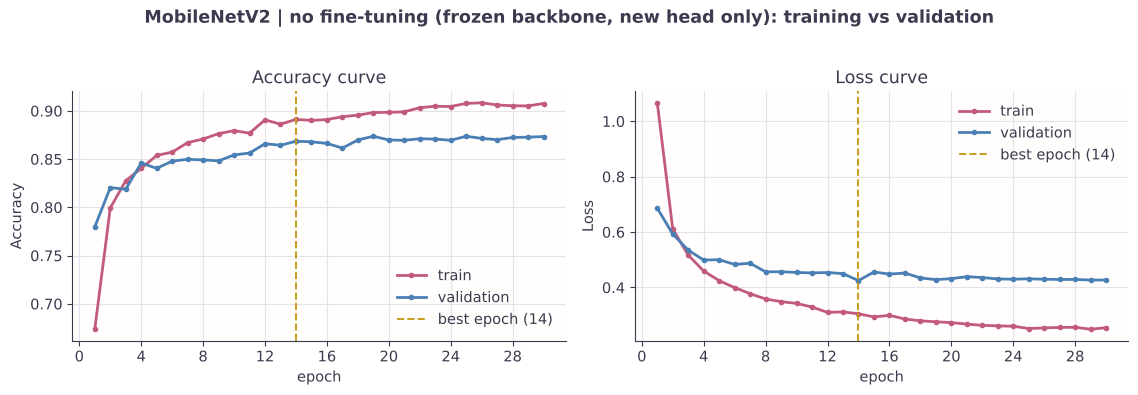

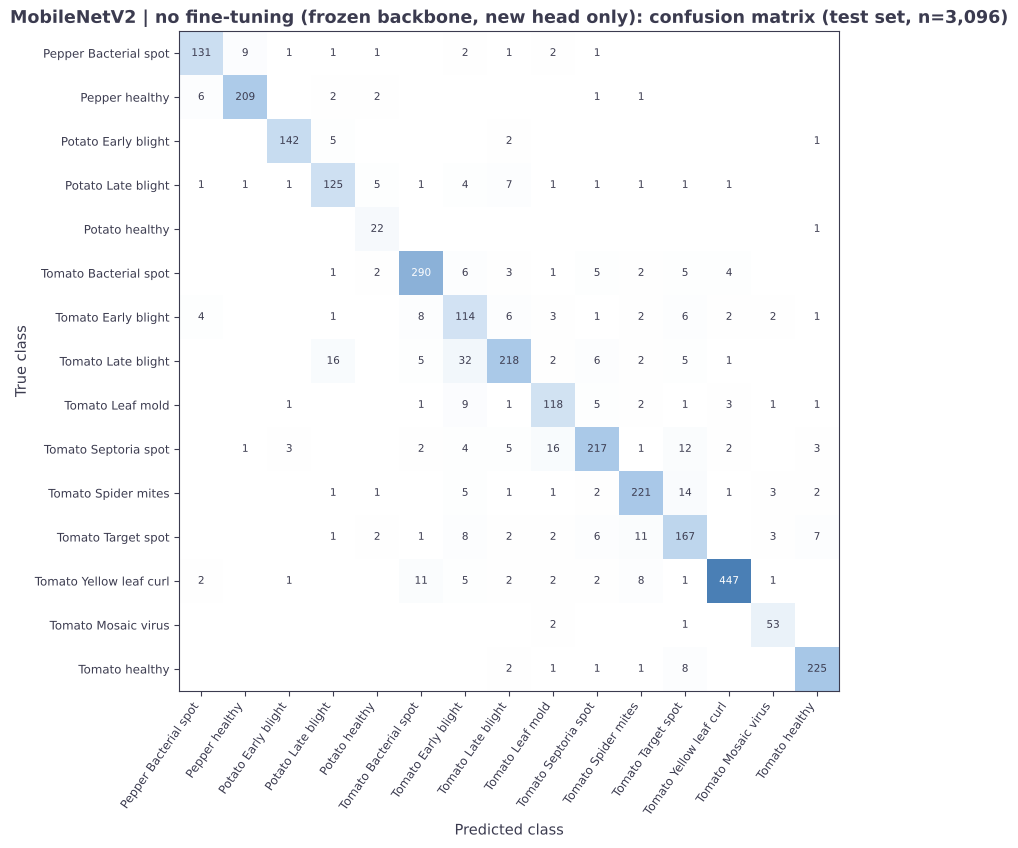

In [7]:
rec = run_experiment("MobileNetV2", finetune=False)
report_experiment(rec)

#### MobileNetV2: with fine-tuning

MobileNetV2 | fine-tuned (all layers trained)


Epoch 01/30 | train loss 0.7615 acc 0.7467 | val loss 0.4640 acc 0.8311 | lr 3.0e-04 |  74.7s  *best*


Epoch 02/30 | train loss 0.3590 acc 0.8760 | val loss 0.3374 acc 0.8747 | lr 3.0e-04 |  70.6s  *best*


Epoch 03/30 | train loss 0.2616 acc 0.9072 | val loss 0.3580 acc 0.8669 | lr 3.0e-04 |  70.5s


Epoch 04/30 | train loss 0.2136 acc 0.9246 | val loss 0.4437 acc 0.8605 | lr 2.9e-04 |  70.0s


...

Epoch 27/30 | train loss 0.0251 acc 0.9907 | val loss 0.0601 acc 0.9761 | lr 1.3e-05 |  72.5s  *best*


Epoch 28/30 | train loss 0.0206 acc 0.9922 | val loss 0.0680 acc 0.9748 | lr 7.3e-06 |  72.4s


Epoch 29/30 | train loss 0.0220 acc 0.9921 | val loss 0.0633 acc 0.9764 | lr 3.3e-06 |  72.0s


Epoch 30/30 | train loss 0.0194 acc 0.9926 | val loss 0.0601 acc 0.9767 | lr 8.2e-07 |  70.4s


=== MobileNetV2 | fine-tuned (all layers trained) ===
Parameters: 2,243,087 total, 2,243,087 trainable | epochs run: 30 | best epoch (lowest val loss): 27
Accuracy 0.9764 | Precision(macro) 0.9583 | Recall(macro) 0.9789 | F1(macro) 0.9665 | F1(weighted) 0.9766
Training time: 2104.8 s (35.1 min) | Testing time: 3.81 s for 3,096 test images (1.23 ms/image)

Classification report (test set):
                         precision    recall  f1-score   support

  Pepper Bacterial spot     0.9933    0.9933    0.9933       149
         Pepper healthy     1.0000    0.9819    0.9909       221
    Potato Early blight     0.9868    0.9933    0.9900       150
     Potato Late blight     0.9074    0.9800    0.9423       150
         Potato healthy     0.6970    1.0000    0.8214        23
  Tomato Bacterial spot     0.9694    0.9937    0.9814       319
    Tomato Early blight     0.9795    0.9533    0.9662       150
     Tomato Late blight     0.9887    0.9164    0.9512       287
       Tomato Leaf mol

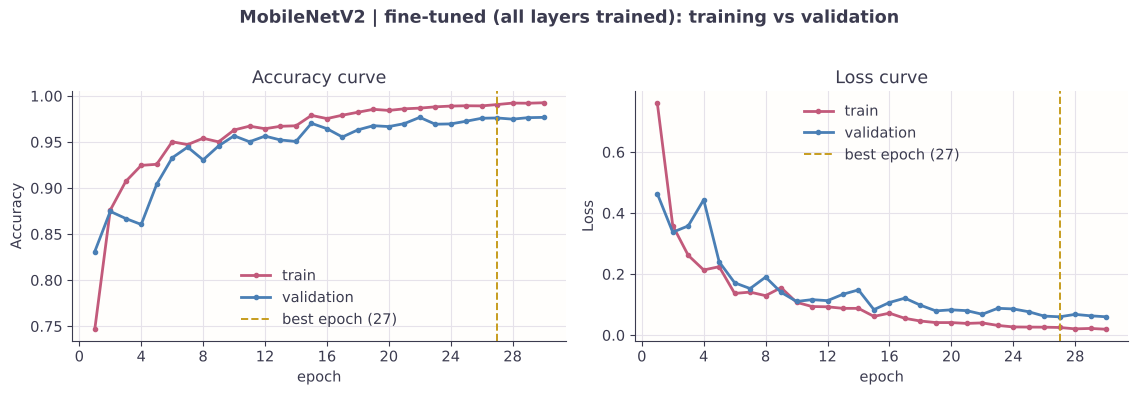

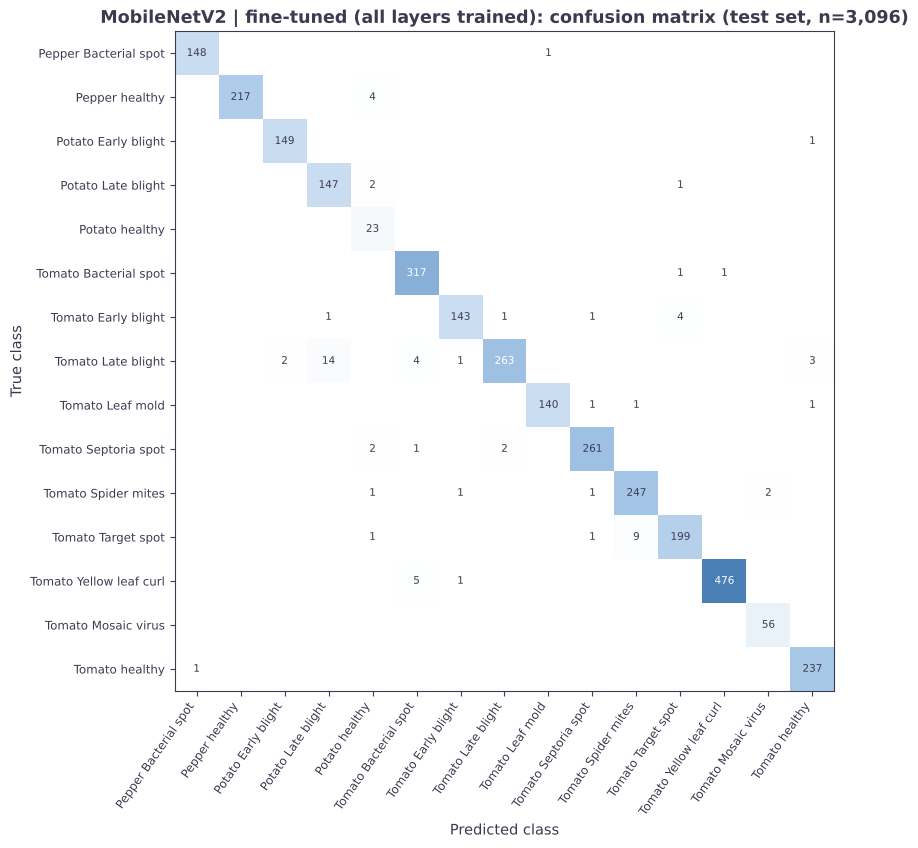

In [8]:
rec = run_experiment("MobileNetV2", finetune=True)
report_experiment(rec)

### 6.2 ResNet-18
#### ResNet-18: without fine-tuning (frozen backbone)

ResNet-18 | no fine-tuning (frozen backbone, new head only)


Extracted 512-d features for 14,446 train + 3,096 val images in 35.6s (backbone frozen, eval mode)


Epoch 01/30 | train loss 1.3611 acc 0.5617 | val loss 0.8193 acc 0.7361 | lr 1.0e-03 |   0.2s  *best*


Epoch 02/30 | train loss 0.8084 acc 0.7305 | val loss 0.6713 acc 0.7943 | lr 1.0e-03 |   0.2s  *best*


Epoch 03/30 | train loss 0.7026 acc 0.7626 | val loss 0.6426 acc 0.7668 | lr 9.9e-04 |   0.2s  *best*


...

Epoch 27/30 | train loss 0.4630 acc 0.8317 | val loss 0.4820 acc 0.8369 | lr 4.3e-05 |   0.2s


Epoch 28/30 | train loss 0.4688 acc 0.8301 | val loss 0.4776 acc 0.8388 | lr 2.4e-05 |   0.2s


Epoch 29/30 | train loss 0.4609 acc 0.8294 | val loss 0.4777 acc 0.8391 | lr 1.1e-05 |   0.2s


Epoch 30/30 | train loss 0.4648 acc 0.8285 | val loss 0.4780 acc 0.8398 | lr 2.7e-06 |   0.3s


=== ResNet-18 | no fine-tuning (frozen backbone, new head only) ===
Parameters: 11,184,207 total, 7,695 trainable | epochs run: 30 | best epoch (lowest val loss): 23
Accuracy 0.8424 | Precision(macro) 0.8175 | Recall(macro) 0.8460 | F1(macro) 0.8281 | F1(weighted) 0.8433
Training time: 41.9 s (0.7 min) | Testing time: 6.06 s for 3,096 test images (1.96 ms/image)

Classification report (test set):
                         precision    recall  f1-score   support

  Pepper Bacterial spot     0.8383    0.9396    0.8861       149
         Pepper healthy     0.9773    0.9729    0.9751       221
    Potato Early blight     0.9726    0.9467    0.9595       150
     Potato Late blight     0.8533    0.8533    0.8533       150
         Potato healthy     0.7037    0.8261    0.7600        23
  Tomato Bacterial spot     0.8650    0.8840    0.8744       319
    Tomato Early blight     0.5714    0.6933    0.6265       150
     Tomato Late blight     0.8320    0.7247    0.7747       287
       Tomato 

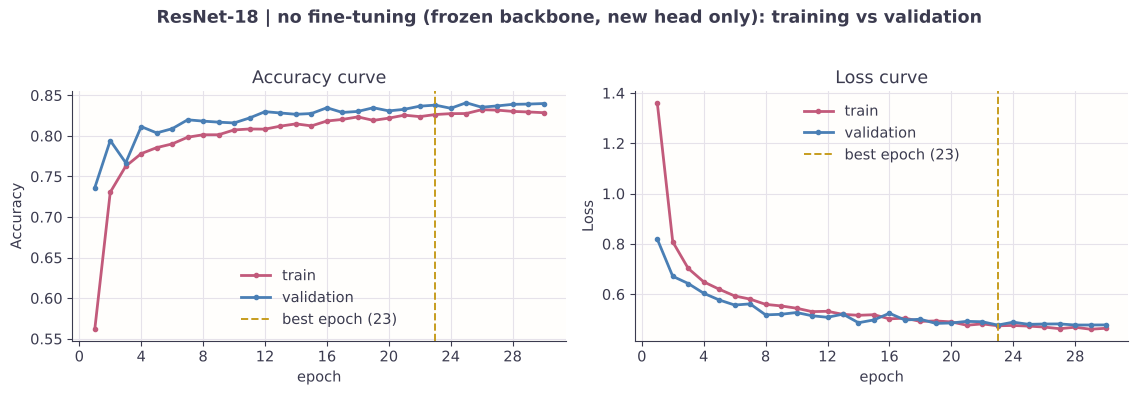

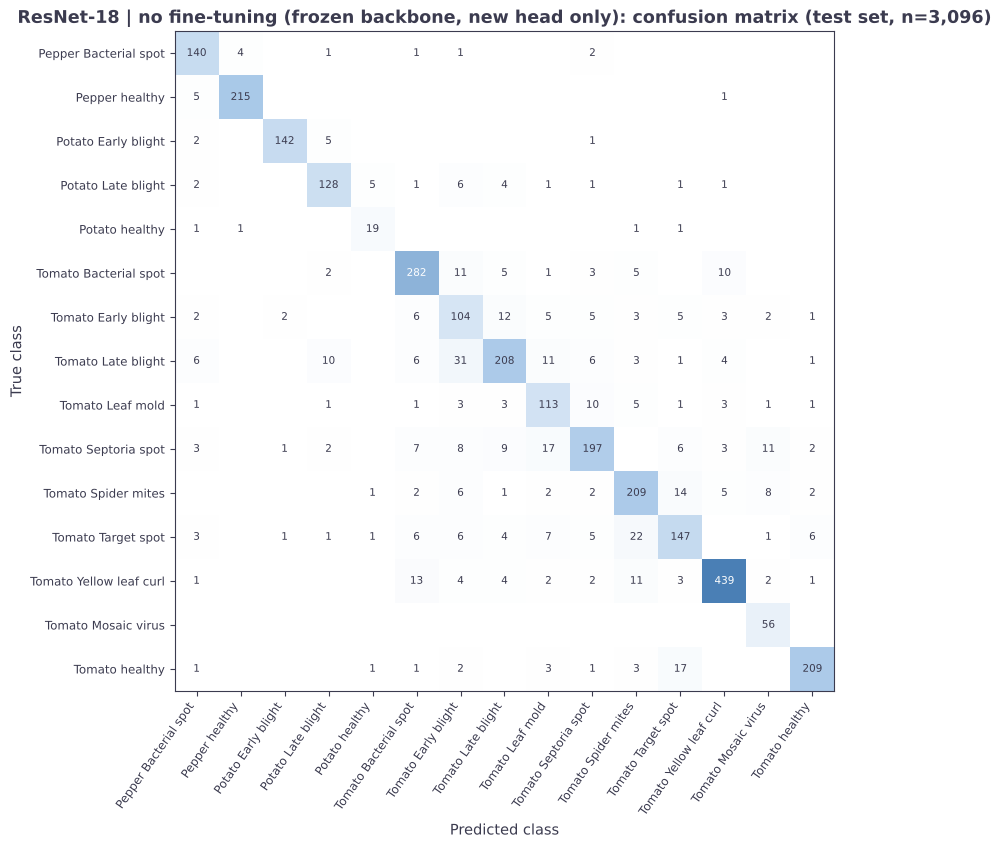

In [9]:
rec = run_experiment("ResNet-18", finetune=False)
report_experiment(rec)

#### ResNet-18: with fine-tuning

ResNet-18 | fine-tuned (all layers trained)


Epoch 01/30 | train loss 0.8567 acc 0.7183 | val loss 0.4458 acc 0.8485 | lr 3.0e-04 | 115.6s  *best*


Epoch 02/30 | train loss 0.4127 acc 0.8573 | val loss 0.3079 acc 0.8866 | lr 3.0e-04 | 124.0s  *best*


Epoch 03/30 | train loss 0.3507 acc 0.8809 | val loss 0.5394 acc 0.8207 | lr 3.0e-04 | 114.5s


Epoch 04/30 | train loss 0.2516 acc 0.9117 | val loss 0.1807 acc 0.9309 | lr 2.9e-04 | 113.9s  *best*


...

Epoch 27/30 | train loss 0.0213 acc 0.9917 | val loss 0.0464 acc 0.9839 | lr 1.3e-05 | 114.7s


Epoch 28/30 | train loss 0.0234 acc 0.9911 | val loss 0.0458 acc 0.9842 | lr 7.3e-06 | 113.9s


Epoch 29/30 | train loss 0.0213 acc 0.9928 | val loss 0.0377 acc 0.9871 | lr 3.3e-06 | 112.4s  *best*


Epoch 30/30 | train loss 0.0203 acc 0.9924 | val loss 0.0387 acc 0.9861 | lr 8.2e-07 | 108.2s


=== ResNet-18 | fine-tuned (all layers trained) ===
Parameters: 11,184,207 total, 11,184,207 trainable | epochs run: 30 | best epoch (lowest val loss): 29
Accuracy 0.9803 | Precision(macro) 0.9708 | Recall(macro) 0.9827 | F1(macro) 0.9762 | F1(weighted) 0.9803
Training time: 3389.1 s (56.5 min) | Testing time: 6.63 s for 3,096 test images (2.14 ms/image)

Classification report (test set):
                         precision    recall  f1-score   support

  Pepper Bacterial spot     1.0000    1.0000    1.0000       149
         Pepper healthy     0.9955    0.9955    0.9955       221
    Potato Early blight     0.9934    1.0000    0.9967       150
     Potato Late blight     0.9548    0.9867    0.9705       150
         Potato healthy     0.8519    1.0000    0.9200        23
  Tomato Bacterial spot     0.9665    0.9937    0.9799       319
    Tomato Early blight     0.9664    0.9600    0.9632       150
     Tomato Late blight     0.9963    0.9443    0.9696       287
       Tomato Leaf mol

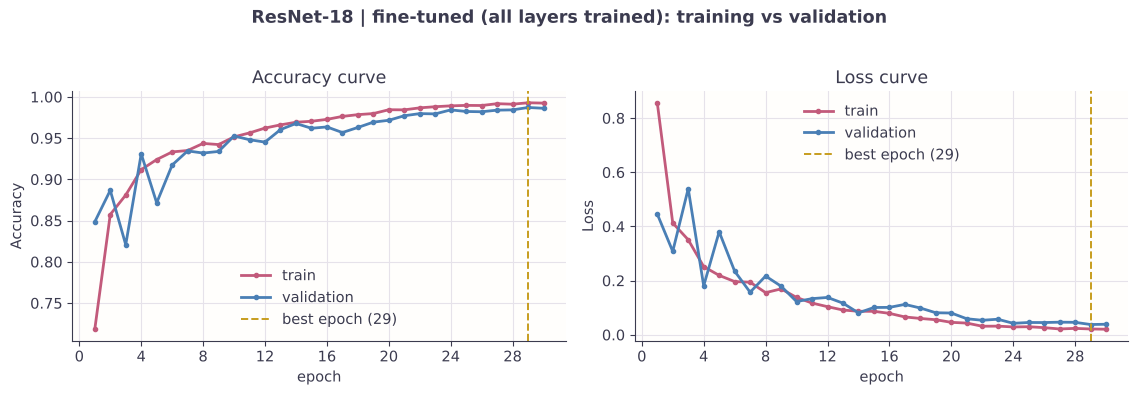

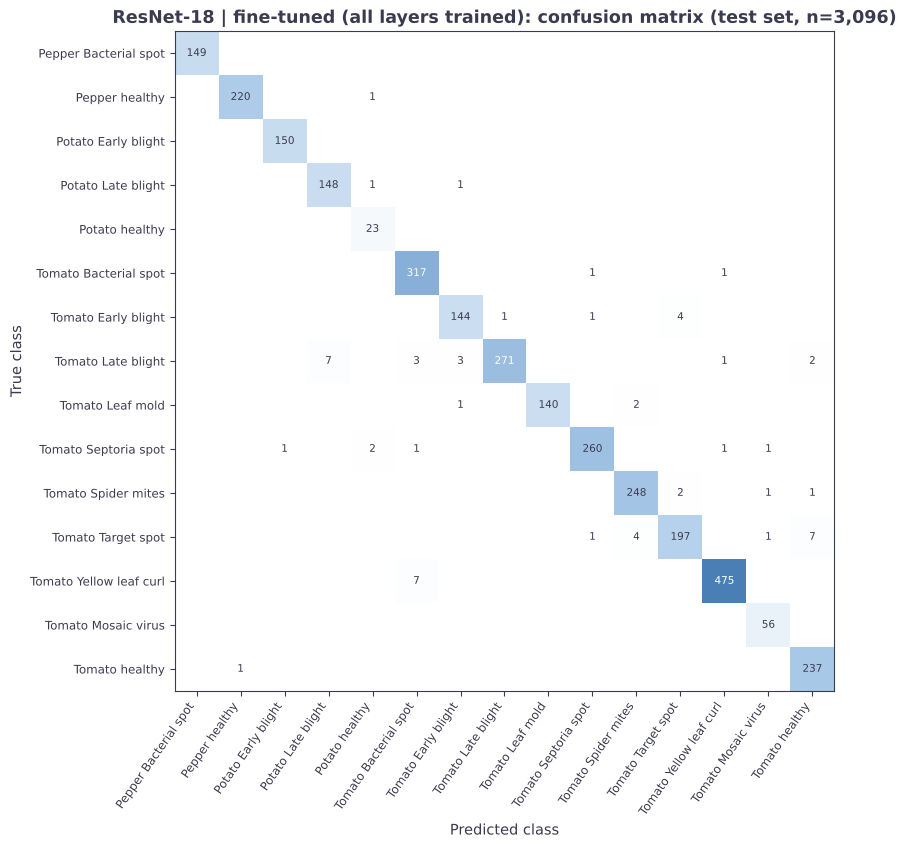

In [10]:
rec = run_experiment("ResNet-18", finetune=True)
report_experiment(rec)

### 6.3 ShuffleNetV2
#### ShuffleNetV2: without fine-tuning (frozen backbone)

ShuffleNetV2 | no fine-tuning (frozen backbone, new head only)


Extracted 1024-d features for 14,446 train + 3,096 val images in 7.8s (backbone frozen, eval mode)


Epoch 01/30 | train loss 2.2192 acc 0.5582 | val loss 1.8377 acc 0.6596 | lr 1.0e-03 |   0.3s  *best*


Epoch 02/30 | train loss 1.6241 acc 0.6772 | val loss 1.4472 acc 0.7009 | lr 1.0e-03 |   0.3s  *best*


Epoch 03/30 | train loss 1.3315 acc 0.7090 | val loss 1.2367 acc 0.7125 | lr 9.9e-04 |   0.3s  *best*


...

Epoch 27/30 | train loss 0.6115 acc 0.8232 | val loss 0.6362 acc 0.8207 | lr 4.3e-05 |   0.3s  *best*


Epoch 28/30 | train loss 0.6148 acc 0.8220 | val loss 0.6358 acc 0.8207 | lr 2.4e-05 |   0.4s  *best*


Epoch 29/30 | train loss 0.6121 acc 0.8239 | val loss 0.6356 acc 0.8204 | lr 1.1e-05 |   0.3s  *best*


Epoch 30/30 | train loss 0.6170 acc 0.8210 | val loss 0.6355 acc 0.8204 | lr 2.7e-06 |   0.3s


=== ShuffleNetV2 | no fine-tuning (frozen backbone, new head only) ===
Parameters: 1,268,979 total, 15,375 trainable | epochs run: 30 | best epoch (lowest val loss): 29
Accuracy 0.8220 | Precision(macro) 0.7900 | Recall(macro) 0.8306 | F1(macro) 0.8043 | F1(weighted) 0.8226
Training time: 18.1 s (0.3 min) | Testing time: 1.31 s for 3,096 test images (0.42 ms/image)

Classification report (test set):
                         precision    recall  f1-score   support

  Pepper Bacterial spot     0.8129    0.8456    0.8289       149
         Pepper healthy     0.9345    0.9683    0.9511       221
    Potato Early blight     0.9286    0.9533    0.9408       150
     Potato Late blight     0.8278    0.8333    0.8306       150
         Potato healthy     0.6364    0.9130    0.7500        23
  Tomato Bacterial spot     0.8045    0.8903    0.8452       319
    Tomato Early blight     0.5818    0.6400    0.6095       150
     Tomato Late blight     0.8559    0.6620    0.7466       287
       Toma

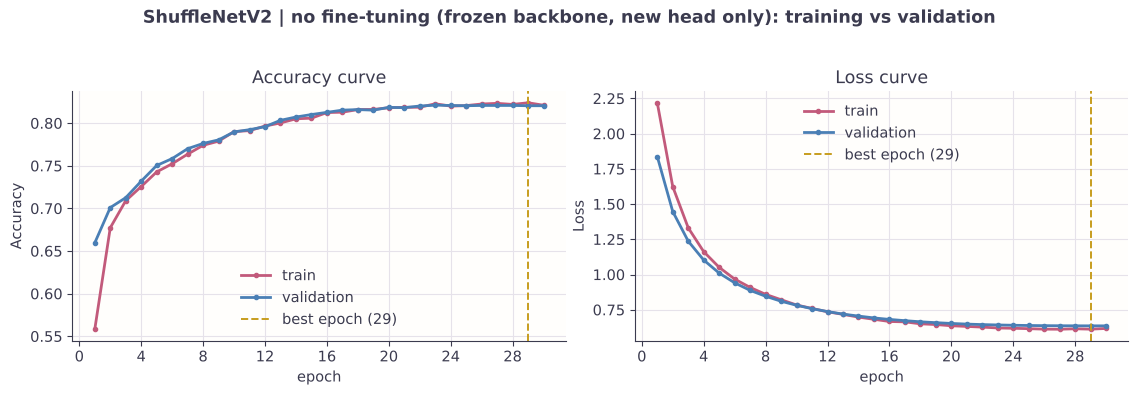

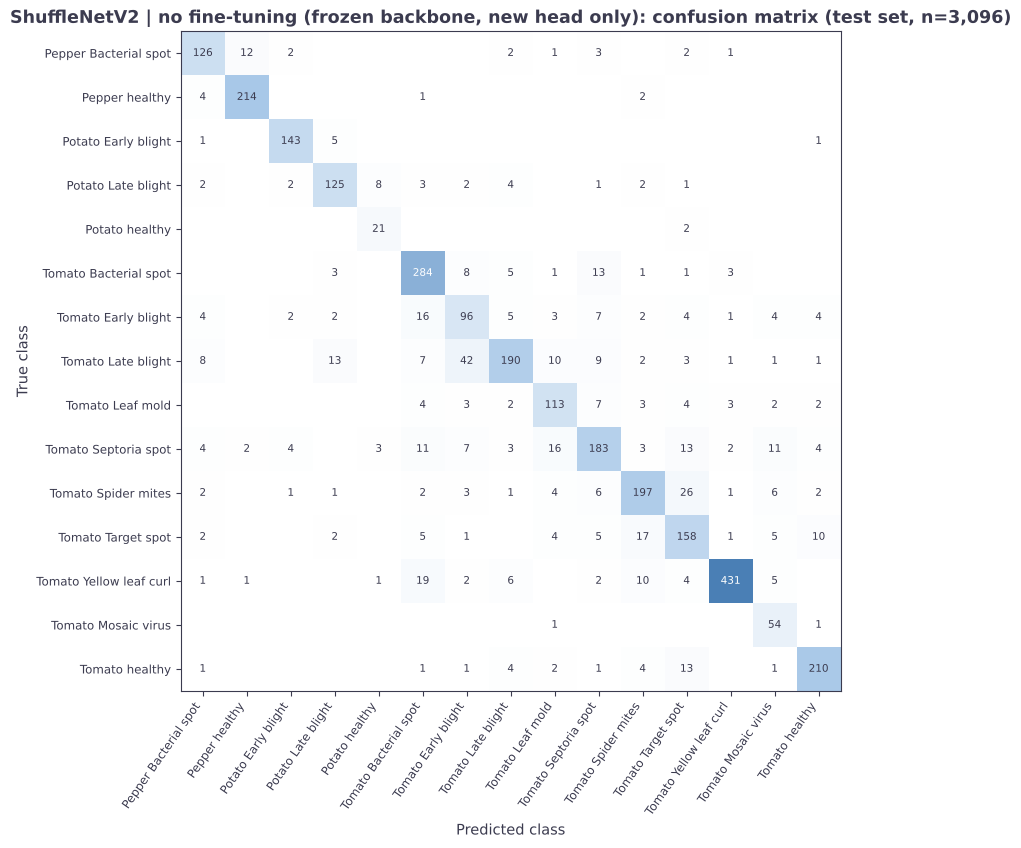

In [11]:
rec = run_experiment("ShuffleNetV2", finetune=False)
report_experiment(rec)

#### ShuffleNetV2: with fine-tuning

ShuffleNetV2 | fine-tuned (all layers trained)


Epoch 01/30 | train loss 1.6264 acc 0.5737 | val loss 0.8025 acc 0.7035 | lr 3.0e-04 |  37.6s  *best*


Epoch 02/30 | train loss 0.5123 acc 0.8352 | val loss 0.4392 acc 0.8372 | lr 3.0e-04 |  38.7s  *best*


Epoch 03/30 | train loss 0.3422 acc 0.8845 | val loss 0.3429 acc 0.8711 | lr 3.0e-04 |  41.2s  *best*


Epoch 04/30 | train loss 0.2711 acc 0.9081 | val loss 0.2716 acc 0.8983 | lr 2.9e-04 |  38.6s  *best*


...

Epoch 27/30 | train loss 0.0486 acc 0.9819 | val loss 0.1063 acc 0.9545 | lr 1.3e-05 |  37.3s


Epoch 28/30 | train loss 0.0512 acc 0.9808 | val loss 0.1112 acc 0.9545 | lr 7.3e-06 |  38.9s


Epoch 29/30 | train loss 0.0454 acc 0.9831 | val loss 0.1022 acc 0.9590 | lr 3.3e-06 |  38.0s


Epoch 30/30 | train loss 0.0445 acc 0.9837 | val loss 0.0992 acc 0.9583 | lr 8.2e-07 |  36.2s


=== ShuffleNetV2 | fine-tuned (all layers trained) ===
Parameters: 1,268,979 total, 1,268,979 trainable | epochs run: 30 | best epoch (lowest val loss): 23
Accuracy 0.9654 | Precision(macro) 0.9460 | Recall(macro) 0.9692 | F1(macro) 0.9554 | F1(weighted) 0.9656
Training time: 1168.8 s (19.5 min) | Testing time: 1.20 s for 3,096 test images (0.39 ms/image)

Classification report (test set):
                         precision    recall  f1-score   support

  Pepper Bacterial spot     0.9932    0.9866    0.9899       149
         Pepper healthy     0.9953    0.9593    0.9770       221
    Potato Early blight     0.9934    1.0000    0.9967       150
     Potato Late blight     0.9673    0.9867    0.9769       150
         Potato healthy     0.7188    1.0000    0.8364        23
  Tomato Bacterial spot     0.9509    0.9718    0.9612       319
    Tomato Early blight     0.9338    0.9400    0.9369       150
     Tomato Late blight     0.9927    0.9512    0.9715       287
       Tomato Leaf mo

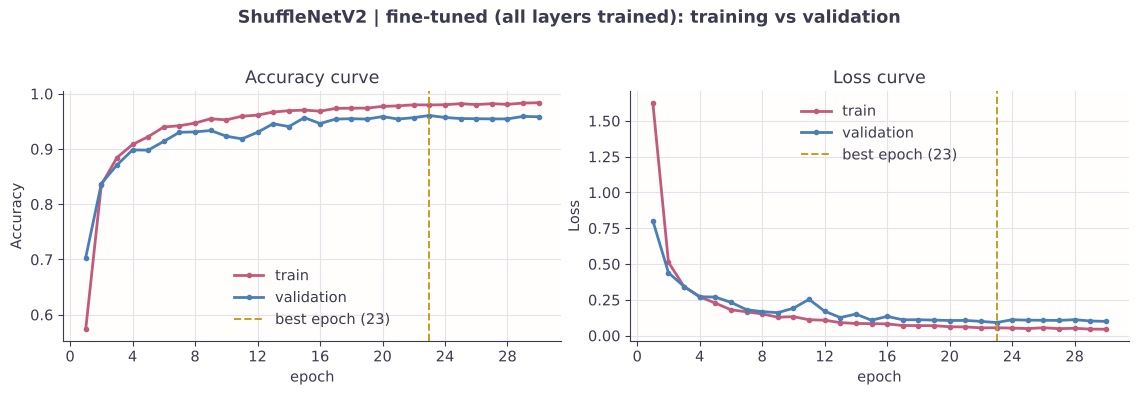

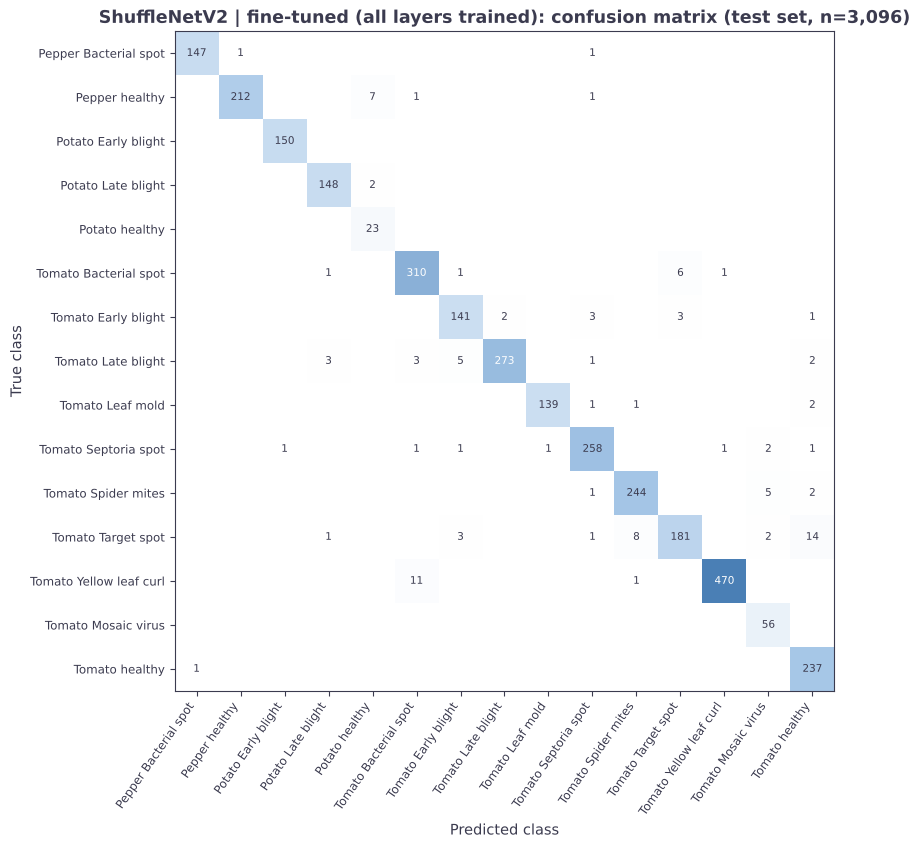

In [12]:
rec = run_experiment("ShuffleNetV2", finetune=True)
report_experiment(rec)

---
## 7. Comparison of all experiments, and over-/under-fitting check

,Model,Mode,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),Train time (min),Test time (s),ms / test image,Trainable params,Best epoch,Train acc @best,Val acc @best
0,MobileNetV2,No fine-tuning,0.8718,0.8451,0.8748,0.8564,0.8733,0.7094,4.9088,1.5855,19215,14,0.8912,0.8685
1,MobileNetV2,Fine-tuned,0.9764,0.9583,0.9789,0.9665,0.9766,35.0806,3.8118,1.2312,2243087,27,0.9907,0.9761
2,ResNet-18,No fine-tuning,0.8424,0.8175,0.8460,0.8281,0.8433,0.6992,6.0622,1.9581,7695,23,0.8262,0.8379
3,ResNet-18,Fine-tuned,0.9803,0.9708,0.9827,0.9762,0.9803,56.4853,6.6312,2.1419,11184207,29,0.9928,0.9871
4,ShuffleNetV2,No fine-tuning,0.8220,0.7900,0.8306,0.8043,0.8226,0.3015,1.3146,0.4246,15375,29,0.8239,0.8204
5,ShuffleNetV2,Fine-tuned,0.9654,0.9460,0.9692,0.9554,0.9656,19.4798,1.2016,0.3881,1268979,23,0.9797,0.9606


,Experiment,Train acc @best,Val acc @best,Gap (train - val),Final val-loss / best val-loss,Verdict
0,MobileNetV2 / No fine-tuning,0.8912,0.8685,0.0226,1.00,underfitting (validation accuracy < 90 %)
1,MobileNetV2 / Fine-tuned,0.9907,0.9761,0.0146,1.00,good fit
2,ResNet-18 / No fine-tuning,0.8262,0.8379,-0.0116,1.00,underfitting (validation accuracy < 90 %)
3,ResNet-18 / Fine-tuned,0.9928,0.9871,0.0057,1.03,good fit
4,ShuffleNetV2 / No fine-tuning,0.8239,0.8204,0.0035,1.00,underfitting (validation accuracy < 90 %)
5,ShuffleNetV2 / Fine-tuned,0.9797,0.9606,0.0191,1.09,good fit


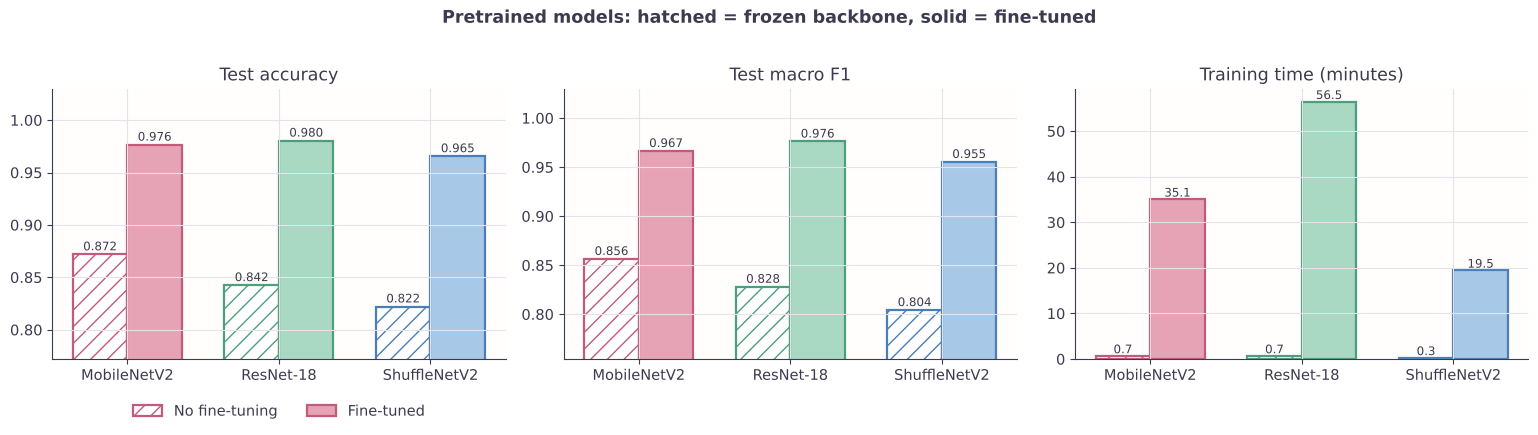

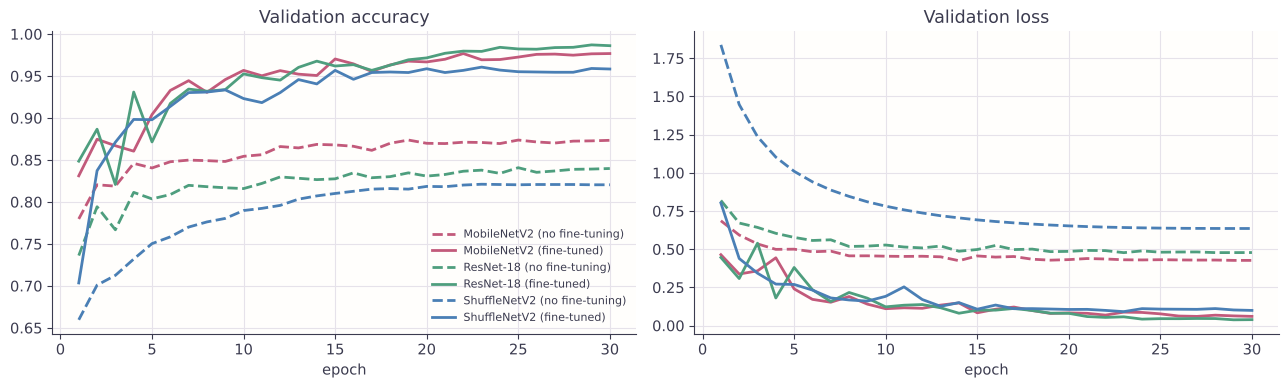

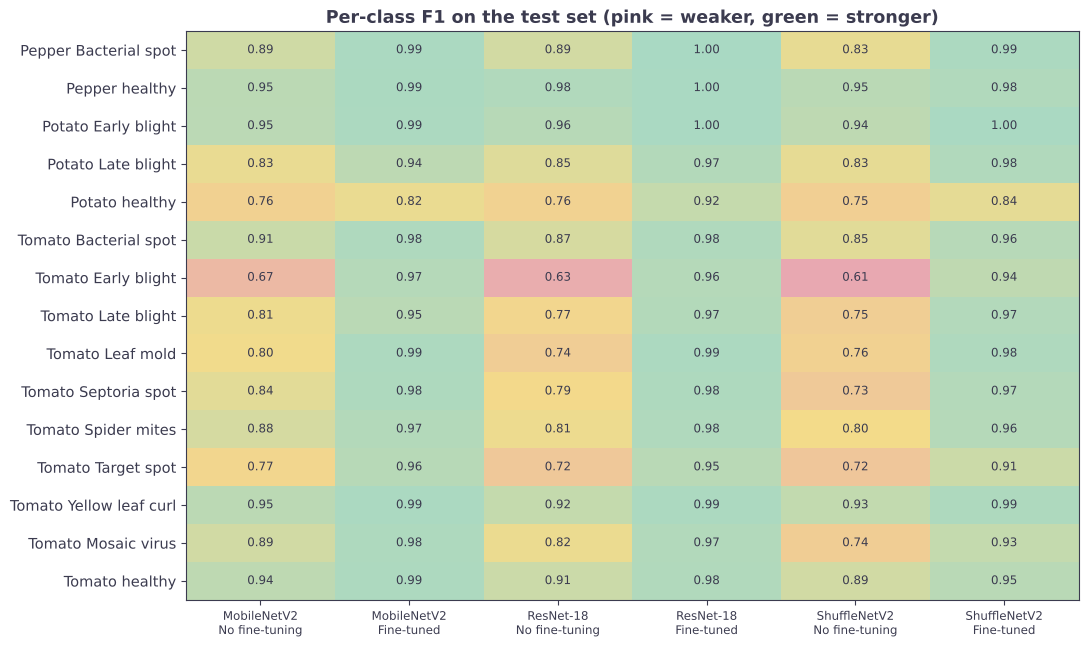

In [13]:
# ---- Side-by-side comparison of all six experiments ----
MODE_NAME = {"frozen": "No fine-tuning", "finetune": "Fine-tuned"}
rows = []
for r in RESULTS:
    m, h, b = r["metrics"], r["hist"], r["best_epoch"] - 1
    rows.append({"Model": r["arch"], "Mode": MODE_NAME[r["mode"]], "Accuracy": m["accuracy"],
                 "Precision (macro)": m["precision_macro"], "Recall (macro)": m["recall_macro"],
                 "F1 (macro)": m["f1_macro"], "F1 (weighted)": m["f1_weighted"],
                 "Train time (min)": r["train_sec"] / 60, "Test time (s)": r["test_sec"],
                 "ms / test image": 1000 * r["test_sec"] / r["n_test"], "Trainable params": r["params_trainable"],
                 "Best epoch": r["best_epoch"], "Train acc @best": h["train_acc"][b], "Val acc @best": h["val_acc"][b]})
summary = pd.DataFrame(rows)
summary["_m"] = summary.Model.map({n: i for i, n in enumerate(PRETRAINED)}); summary["_k"] = summary.Mode.map({"No fine-tuning": 0, "Fine-tuned": 1})
summary = summary.sort_values(["_m", "_k"]).drop(columns=["_m", "_k"]).reset_index(drop=True)
summary.to_csv(RESULT_DIR / "submission2_summary.csv", index=False)
display(summary.round(4))

# ---- Over-/under-fitting check on every run ----
diag = []
for r in RESULTS:
    h, b = r["hist"], r["best_epoch"] - 1
    gap = h["train_acc"][b] - h["val_acc"][b]; vgrow = h["val_loss"][-1] / min(h["val_loss"])
    if h["val_acc"][b] < 0.90: verdict = "underfitting (validation accuracy < 90 %)"
    elif gap > 0.05 or vgrow > 1.25: verdict = "overfitting"
    else: verdict = "good fit"
    diag.append({"Experiment": f"{r['arch']} / {MODE_NAME[r['mode']]}", "Train acc @best": round(h["train_acc"][b], 4),
                 "Val acc @best": round(h["val_acc"][b], 4), "Gap (train - val)": round(gap, 4),
                 "Final val-loss / best val-loss": round(vgrow, 2), "Verdict": verdict})
display(pd.DataFrame(diag))

# ---- Charts ----
colors = {"MobileNetV2": PAL["rose"], "ResNet-18": PAL["mint"], "ShuffleNetV2": PAL["blue"]}
dcolors = {"MobileNetV2": PAL["rose_d"], "ResNet-18": PAL["mint_d"], "ShuffleNetV2": PAL["blue_d"]}
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.3))
x = np.arange(len(PRETRAINED)); w = 0.36
for a, col, ttl in [(ax[0], "Accuracy", "Test accuracy"), (ax[1], "F1 (macro)", "Test macro F1")]:
    for k, mode in enumerate(["No fine-tuning", "Fine-tuned"]):
        vals = [summary[(summary.Model == mdl) & (summary.Mode == mode)][col].iloc[0] for mdl in PRETRAINED]
        bars = a.bar(x + (k - 0.5) * w, vals, w, color=[colors[m] if k else "#FFFFFF" for m in PRETRAINED],
                     edgecolor=[dcolors[m] for m in PRETRAINED], linewidth=1.6, hatch="" if k else "//", label=mode)
        for bx, v in zip(bars, vals): a.text(bx.get_x() + bx.get_width() / 2, v + 0.004, f"{v:.3f}", ha="center", fontsize=8.5)
    a.set_xticks(x); a.set_xticklabels(PRETRAINED); a.set_title(ttl); a.set_ylim(min(0.8, summary[col].min() - 0.05), 1.03)
    if a is ax[0]: a.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
for k, mode in enumerate(["No fine-tuning", "Fine-tuned"]):
    vals = [summary[(summary.Model == mdl) & (summary.Mode == mode)]["Train time (min)"].iloc[0] for mdl in PRETRAINED]
    bars = ax[2].bar(x + (k - 0.5) * w, vals, w, color=[colors[m] if k else "#FFFFFF" for m in PRETRAINED],
                     edgecolor=[dcolors[m] for m in PRETRAINED], linewidth=1.6, hatch="" if k else "//", label=mode)
    for bx, v in zip(bars, vals): ax[2].text(bx.get_x() + bx.get_width() / 2, v + 0.01 * summary["Train time (min)"].max(), f"{v:.1f}", ha="center", fontsize=8.5)
ax[2].set_xticks(x); ax[2].set_xticklabels(PRETRAINED); ax[2].set_title("Training time (minutes)")
plt.suptitle("Pretrained models: hatched = frozen backbone, solid = fine-tuned", fontweight="bold", y=1.02); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r in RESULTS:
    ls = "-" if r["mode"] == "finetune" else "--"
    ax[0].plot(range(1, len(r["hist"]["val_acc"]) + 1), r["hist"]["val_acc"], ls, color=dcolors[r["arch"]], lw=2, label=f"{r['arch']} ({MODE_NAME[r['mode']].lower()})")
    ax[1].plot(range(1, len(r["hist"]["val_loss"]) + 1), r["hist"]["val_loss"], ls, color=dcolors[r["arch"]], lw=2)
ax[0].set_title("Validation accuracy"); ax[1].set_title("Validation loss")
for a in ax: a.set_xlabel("epoch")
ax[0].legend(frameon=False, fontsize=8, ncol=1); plt.tight_layout(); plt.show()

f1 = pd.DataFrame({f"{r['arch']}\n{MODE_NAME[r['mode']]}": r["per_class_f1"] for r in RESULTS}, index=LABELS)
fig, ax = plt.subplots(figsize=(11, 6.6)); ax.grid(False)
im = ax.imshow(f1.values, cmap=HEAT_CMAP, vmin=max(0.0, f1.values.min() - 0.02), vmax=1.0, aspect="auto")
ax.set_xticks(range(f1.shape[1])); ax.set_xticklabels(f1.columns, fontsize=8.5); ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(LABELS)
for i in range(f1.shape[0]):
    for j in range(f1.shape[1]): ax.text(j, i, f"{f1.values[i, j]:.2f}", ha="center", va="center", fontsize=8.5)
ax.set_title("Per-class F1 on the test set (pink = weaker, green = stronger)", fontweight="bold")
for s in ax.spines.values(): s.set_visible(True)
plt.tight_layout(); plt.show()

### 8. Analysis: results, over-/under-fitting and the fixes applied

**Setting.** All runs use 64×64 inputs on CPU, a stratified 70/15/15 split (seed 42), class-weighted cross-entropy and 30 epochs. Test set = 3,096 images; every number below is read from the tables above.

**1. Fine-tuning matters a lot.** Training all layers beat the frozen backbone for every model:

| Model | Frozen: accuracy / macro-F1 | Fine-tuned: accuracy / macro-F1 | Gain in accuracy |
|---|---|---|---|
| MobileNetV2 | 0.8718 / 0.8564 | 0.9764 / 0.9665 | +10.5 points |
| ResNet-18 | 0.8424 / 0.8281 | 0.9803 / 0.9762 | +13.8 points |
| ShuffleNetV2 | 0.8220 / 0.8043 | 0.9654 / 0.9554 | +14.3 points |

ImageNet features are general (edges, textures, colours) but were learned on 224×224 photos of objects. On tiny 64×64 leaf images they separate visually distinct diseases but not similar ones, so a head trained on frozen features cannot adapt them.

**2. Over-/under-fitting diagnosis.** The three frozen models are **underfitting**: validation accuracy stays below 90 % and train accuracy is no higher (0.83 to 0.89 at the best epoch), so the model, not the data volume, is the limit. The three fine-tuned models are a **good fit**: train−validation gap is 0.6 to 1.9 points, and the final validation loss is within 0 to 9 % of its best value (ShuffleNetV2 is the largest at 1.09, a mild sign of the start of overfitting after epoch 23).

**3. Fixes that were applied.** For underfitting: unfreeze the backbone and add augmentation (that is exactly the fine-tuned mode). For overfitting risk: dropout 0.2 in the head, weight decay, augmentation, a cosine learning-rate schedule and restoring the best-validation-loss checkpoint. Not applied (not needed): more regularisation, because fine-tuned gaps are already small.

**4. Which model?**
- **ResNet-18 fine-tuned** is the most accurate (0.9803) but also the slowest to train (56.5 min) and has the most trainable parameters (11.2 M).
- **MobileNetV2 fine-tuned** is within 0.4 points (0.9764) and trains in 35.1 min with 2.2 M parameters.
- **ShuffleNetV2 fine-tuned** is the fastest to train (19.5 min) and to test (0.39 ms/image) at 0.9654.
The differences between the two best models are small (about 12 images out of 3,096), so with a single seed we should not claim ResNet-18 is truly better than MobileNetV2. MobileNetV2 is the best accuracy-for-cost compromise.

**5. Compared with the custom CNN (Submission 3).** The from-scratch CNN (263,839 parameters, test accuracy 0.9325, about 13.8 min) is clearly better than any frozen backbone and clearly worse than any fine-tuned one, with about 1/5 to 1/40 of the trainable parameters of the fine-tuned models. Transfer learning wins on accuracy; the small custom network wins on size.

**Honest limits.** (a) 64×64 inputs and CPU training were used for feasibility; at 224×224 on a GPU the frozen results would probably improve. (b) ResNet-18 replaces the ResNet-50 named in the proposal to keep the run time practical. (c) Frozen mode caches features, so it uses no augmentation, and its train time (under 1 min) includes feature extraction. (d) Test times are single measurements on a shared CPU and are only roughly comparable. (e) PlantVillage contains near-duplicate images of the same leaf, so a random split can overestimate accuracy on new photos.

---
## Submission checklist
* [x] Three pretrained architectures (MobileNetV2, ResNet-18, ShuffleNetV2), each trained for 30 epochs
* [x] Every model run with and without fine-tuning (six experiments)
* [x] Accuracy and loss curves (train vs validation) for every experiment
* [x] Classification report (precision, recall, F1 per class) for every experiment
* [x] Confusion matrix on the test set for every experiment
* [x] Accuracy, precision, recall, F1, training time and testing time reported for every experiment
* [x] Over-/under-fitting diagnosis and written analysis

All cells were run top to bottom before saving, so every table and plot is visible in this notebook.